# Card fraud model: from the Feast offline store to a model in MLflow

The same 7 steps as the Kubeflow pipeline `train_fraud_model` (`ml/pipeline.py`), run here one by one so every
intermediate result can be looked at. The heavy lifting lives in the library `ml/fraud_ml` that the pipeline
components call too, so the notebook and the pipeline cannot drift apart.

| Step | What | Library |
|---|---|---|
| 1 | Labels as known on `label_as_of` (Delta time travel) -> 2-column label table, merged with the payments | `TrainingDataService` |
| 2 | Point-in-time features from Feast (`fraud_model_v1`) | `TrainingDataService.historical_features` |
| 3 | Data validation | `DataValidator` |
| 4 | Time split with 60-day gaps | `TimeSplitter` |
| 5 | Logistic regression baseline + distributed XGBoost (Spark, 2 workers), both saved to files | `FraudModelTrainer`, `joblib` |
| 6 | Thresholds on validation, metrics on test | `ModelEvaluator` |
| 7 | Log to MLflow (the pipeline registers; the notebook only tracks) | `ModelRegistry` |

Runs in the `notebook` container (image `fraud/ml-train`, compose network): Spark local[2], S3 = SeaweedFS. The JVM's
own log (Spark, XGBoost workers) goes to `docker logs notebook`, not into the cells (`infra/conf/notebook/ipython_kernel_config.py`).

In [1]:
import datetime as dt
import logging
import os
import sys
import time
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm without ipywidgets: warns on import

import feast.infra.offline_stores.contrib.spark_offline_store.spark  # noqa: F401  (loaded before the filter below)
import matplotlib.pyplot as plt
import pandas as pd
from feast import FeatureStore

from fraud_ml.data import TrainingDataService
from fraud_ml.evaluate import ModelEvaluator
from fraud_ml.registry import ModelRegistry
from fraud_ml.spark import session
from fraud_ml.split import TimeSplitter
from fraud_ml.steps import REPO, feature_names
from fraud_ml.train import FraudModelTrainer
from fraud_ml.validation import DataValidator

# The cells show what this notebook prints. Feast warns that its Spark offline store is alpha, and its modules
# reset the RuntimeWarning filters when they load: this filter comes after them (the store module is imported
# above instead of on the first query). MLflow prints the run URL after every call: the last cell prints the run
# id once. xgboost.spark logs its progress (2 workers, parameters) to stderr: printed as normal output instead.
warnings.filterwarnings("ignore", message=".*experimental feature in alpha", category=RuntimeWarning)
os.environ["MLFLOW_SUPPRESS_PRINTING_URL_TO_STDOUT"] = "true"
logging.getLogger("XGBoost-PySpark").addHandler(logging.StreamHandler(sys.stdout))

LABEL_AS_OF = dt.date(2026, 10, 15)
NEGATIVE_RATE = 0.02
SERVICE = "fraud_model_v1"
pd.set_option("display.width", 200, "display.max_columns", 30)
spark = session("notebook", driver_memory="2500m")
store = FeatureStore(repo_path=REPO)
svc = TrainingDataService(spark, LABEL_AS_OF, NEGATIVE_RATE, SERVICE)
FEATURES = feature_names(SERVICE)
print(len(FEATURES), "features:", FEATURES)

20 features: ['txn_count_30d', 'distinct_merchants_30d', 'avg_amount_90d', 'std_amount_90d', 'ecom_ratio_90d', 'foreign_txn_ratio_90d', 'dispute_count_180d', 'auth_count_10m_now', 'amount_sum_1h_now', 'distinct_merchants_1h_now', 'distinct_units_1h_now', 'days_since_last_active', 'amount', 'amount_to_avg_ratio', 'days_since_card_issue', 'is_new_device', 'is_ecom', 'is_foreign', 'is_night', 'is_otp']


## 1. Labels as of `label_as_of`, merged with the payments

`gold.label_transaction` is MERGEd once per day as disputes arrive; each commit is tagged `label_as_of=D`.
Reading the version of `LABEL_AS_OF` gives the labels exactly as the bank knew them that day. Only mature
payments (older than 60 days, the longest dispute delay) are kept. The result is the **label table with 2
columns**, `transaction_id` and `is_fraud`.

In [2]:
print("input versions:", svc.data_versions())
labels = svc.labels()
labels.groupBy("is_fraud").count().show()
labels.show(5)

input versions: {'label_transaction': 14, 'feat_card_txn_stats_daily': 7, 'dim_card': 15, 'feat_card_auth_rt': 235, 'feat_card_device': 103}


+--------+-------+
|is_fraud|  count|
+--------+-------+
|       1|  22552|
|       0|7497992|
+--------+-------+



+----------------+--------+
|  transaction_id|is_fraud|
+----------------+--------+
|txn_000000578d7e|       0|
|txn_000000578e1f|       0|
|txn_000000578f38|       0|
|txn_000000578eb4|       0|
|txn_000000578f69|       0|
+----------------+--------+
only showing top 5 rows


Merge with the payment (request fields the switch sends) and its device, split by date, and downsample the
negatives of the train period to 2% (sample weight 50). Entity timestamp = payment time - 1 ms: the
point-in-time join may only use feature rows written before the payment.

In [3]:
t0 = time.time()
entities = svc.entities().cache()
print(entities.groupBy("split", "is_fraud").count().orderBy("split", "is_fraud").toPandas())
entities.select("transaction_id", "is_fraud", "card_id", "device_id", "event_timestamp", "amount_vnd", "channel",
                "currency", "auth_method", "split", "sample_weight").show(5, truncate=False)
print(f"{time.time() - t0:.0f} s")

   split  is_fraud   count
0   test         0  469346
1   test         1    1426
2  train         0  112030
3  train         1   16875
4    val         0  469556
5    val         1    1429
+----------------+--------+-------------+------------+-----------------------+----------+-------+--------+----------------------+-----+-------------+
|transaction_id  |is_fraud|card_id      |device_id   |event_timestamp        |amount_vnd|channel|currency|auth_method           |split|sample_weight|
+----------------+--------+-------------+------------+-----------------------+----------+-------+--------+----------------------+-----+-------------+
|txn_0000000001f6|0       |card_6a7833e2|dev_d4d5149b|2024-01-01 04:16:24.999|1494000   |ecom   |VND     |unknown_pre_regulation|train|50.0         |
|txn_000000000359|0       |card_a0fbf322|dev_4a7d0aae|2024-01-01 10:15:34.999|516000    |ecom   |VND     |unknown_pre_regulation|train|50.0         |
|txn_000000000aed|0       |card_28537460|-           |2024-01

## 2. Point-in-time features from the Feast offline store

In [4]:
t0 = time.time()
df = svc.historical_features(entities, store)
print(df.shape, f"{time.time() - t0:.0f} s")
df[["transaction_id", "is_fraud", "split", *FEATURES]].head()

(1070662, 42) 294 s


,transaction_id,is_fraud,split,txn_count_30d,distinct_merchants_30d,avg_amount_90d,std_amount_90d,ecom_ratio_90d,foreign_txn_ratio_90d,dispute_count_180d,auth_count_10m_now,amount_sum_1h_now,distinct_merchants_1h_now,distinct_units_1h_now,days_since_last_active,amount,amount_to_avg_ratio,days_since_card_issue,is_new_device,is_ecom,is_foreign,is_night,is_otp
0,txn_0000002ebd9d,0,train,4.0,4.0,587500.000000,7.785665e+05,0.600000,0.000000,0.0,0,0,0,0,20.467928,500000.0,0.851064,1764.466366,0,0,0,0,0
1,txn_000000630071,0,val,3.0,3.0,926666.666667,1.823104e+06,0.500000,0.000000,0.0,0,0,0,0,7.788808,134000.0,0.144604,2200.787245,0,0,0,0,0
2,txn_0000006ff65e,0,test,3.0,1.0,502666.666667,3.901994e+05,1.000000,0.166667,0.0,0,0,0,0,2.526655,437000.0,0.869363,2308.525093,0,1,0,0,1
3,txn_00000070f401,0,test,4.0,2.0,493285.714286,3.619845e+05,1.000000,0.142857,0.0,0,0,0,0,7.646956,80000.0,0.162178,2316.645394,0,1,0,0,1
4,txn_0000005e868a,0,val,3.0,3.0,292571.428571,4.067396e+05,0.857143,0.000000,0.0,0,0,0,0,15.804387,151000.0,0.516113,2966.734167,0,0,0,0,0


In [5]:
summary = pd.DataFrame({"null_share": df[FEATURES].isna().mean(), "mean": df[FEATURES].mean(),
                        "mean_fraud": df[df.is_fraud == 1][FEATURES].mean(),
                        "mean_legit": df[df.is_fraud == 0][FEATURES].mean()}).round(4)
summary

,null_share,mean,mean_fraud,mean_legit
txn_count_30d,0.0061,2.8528,2.9974,2.8501
distinct_merchants_30d,0.0061,2.5761,2.6854,2.5740
avg_amount_90d,0.0061,440920.1304,454874.4876,440661.9123
std_amount_90d,0.0061,438337.9314,458106.7097,437972.1204
ecom_ratio_90d,0.0061,0.7192,0.7183,0.7193
foreign_txn_ratio_90d,0.0061,0.0402,0.0398,0.0402
dispute_count_180d,0.0061,0.0480,0.0458,0.0481
auth_count_10m_now,0.0000,0.0007,0.0008,0.0007
amount_sum_1h_now,0.0000,1543.7514,2019.8175,1534.8139
distinct_merchants_1h_now,0.0000,0.0037,0.0040,0.0036


## 3. Data validation

In [6]:
v = DataValidator(FEATURES)
report = pd.DataFrame(v.validate(df))
print(report.ok.value_counts())
report[~report.ok] if (~report.ok).any() else report.tail(8)

ok
True    48
Name: count, dtype: int64


,check,ok,detail
40,schema: is_otp numeric,True,int64
41,nulls: is_otp <= 5%,True,0.0
42,volume: train rows and frauds,True,"{'rows': 128905, 'frauds': 16875}"
43,"labels: train fraud rate in [0.03, 0.4]",True,0.13091
44,volume: val rows and frauds,True,"{'rows': 470985, 'frauds': 1429}"
45,"labels: val fraud rate in [0.0005, 0.02]",True,0.00303
46,volume: test rows and frauds,True,"{'rows': 470772, 'frauds': 1426}"
47,"labels: test fraud rate in [0.0005, 0.02]",True,0.00303


## 4. Time split with 60-day gaps

In [7]:
splitter = TimeSplitter(LABEL_AS_OF)
print(splitter.windows())
day = pd.to_datetime(df.request_ts).dt.date
splitter.check({s: (day[df.split == s].min(), day[df.split == s].max()) for s in ("train", "val", "test")})
train, val, test = (df[df.split == s] for s in ("train", "val", "test"))
pd.DataFrame({s: {"rows": len(p), "frauds": int(p.is_fraud.sum()), "fraud_rate": round(p.is_fraud.mean(), 5)}
              for s, p in (("train", train), ("val", val), ("test", test))})

{'train': (datetime.date(2024, 1, 1), datetime.date(2025, 12, 19)), 'val': (datetime.date(2026, 2, 17), datetime.date(2026, 4, 18)), 'test': (datetime.date(2026, 6, 17), datetime.date(2026, 8, 16))}


,train,val,test
rows,128905.00000,470985.00000,470772.00000
frauds,16875.00000,1429.00000,1426.00000
fraud_rate,0.13091,0.00303,0.00303


## 5. Baseline and distributed XGBoost

`SparkXGBClassifier(num_workers=2)`: two Spark tasks train one model together (rows sharded, histograms
all-reduced each round). In the pipeline the two workers are executor pods on Kubernetes.

In [8]:
trainer = FraudModelTrainer(FEATURES, num_workers=2)
t0 = time.time()
baseline = trainer.fit_baseline(train)
print(f"baseline {time.time() - t0:.0f} s")
t0 = time.time()
booster = trainer.fit_xgboost(spark, train, val)
print(f"xgboost {time.time() - t0:.0f} s, best iteration {booster.best_iteration}")

baseline 3 s


Running xgboost-3.2.0 on 2 workers with
	booster params: {'objective': 'binary:logistic', 'colsample_bytree': 0.8, 'device': 'cpu', 'eval_metric': 'aucpr', 'learning_rate': 0.08, 'max_depth': 6, 'min_child_weight': 5.0, 'random_state': 42, 'subsample': 0.8, 'tree_method': 'hist', 'nthread': 1}
	train_call_kwargs_params: {'early_stopping_rounds': 30, 'verbose_eval': True, 'num_boost_round': 400}
	dmatrix_kwargs: {'nthread': 1, 'missing': nan}


Finished xgboost training!


xgboost 56 s, best iteration 248


Save both models to files next to the notebook (`notebooks/models/`, gitignored), as the pipeline's `train` step
does on S3: joblib for the baseline and the booster, plus XGBoost's own JSON format, which loads in any XGBoost
version (the KServe predictor ships that file). The reloaded booster must give exactly the same scores.

In [9]:
from pathlib import Path

import joblib

out = Path("models")
out.mkdir(exist_ok=True)
joblib.dump(baseline, out / "baseline_logreg.joblib")    # sklearn pipeline: impute + scale + logistic regression
joblib.dump(booster, out / "xgboost.joblib")
booster.save_model(str(out / "xgboost.json"))
for f in sorted(out.iterdir()):
    print(f"{f}  {f.stat().st_size / 1024:.0f} KB")
reloaded = joblib.load(out / "xgboost.joblib")
print("reloaded booster gives the same scores:",
      (FraudModelTrainer.predict(reloaded, val) == FraudModelTrainer.predict(booster, val)).all())

models/baseline_logreg.joblib  3 KB
models/xgboost.joblib  941 KB
models/xgboost.json  1413 KB


reloaded booster gives the same scores: True


## 6. Evaluation: thresholds on validation, metrics on test

In [10]:
ev = ModelEvaluator()
s_val, s_test = FraudModelTrainer.predict(booster, val), FraudModelTrainer.predict(booster, test)
t = ev.thresholds(val.is_fraud.to_numpy(), s_val)
b_val, b_test = (baseline.predict_proba(p[FEATURES])[:, 1] for p in (val, test))
metrics = pd.DataFrame({
    "xgboost": ev.metrics(test.is_fraud.to_numpy(), s_test, t),
    "logistic_regression": ev.metrics(test.is_fraud.to_numpy(), b_test, ev.thresholds(val.is_fraud.to_numpy(), b_val))})
print("thresholds", t)
metrics.round(4)

thresholds {'t_low': 0.0030914018861949444, 't_high': 0.05667918547987938}


,xgboost,logistic_regression
pr_auc,0.8579,0.5842
roc_auc,0.9875,0.9861
recall_at_1pct_fpr,0.9137,0.9144
precision_at_t_high,0.7158,0.6566
recall_at_t_high,0.8955,0.6381
decline_rate,0.0038,0.0029
step_up_rate,0.0095,0.0099
test_rows,470772.0000,470772.0000
test_fraud_rate,0.0030,0.0030


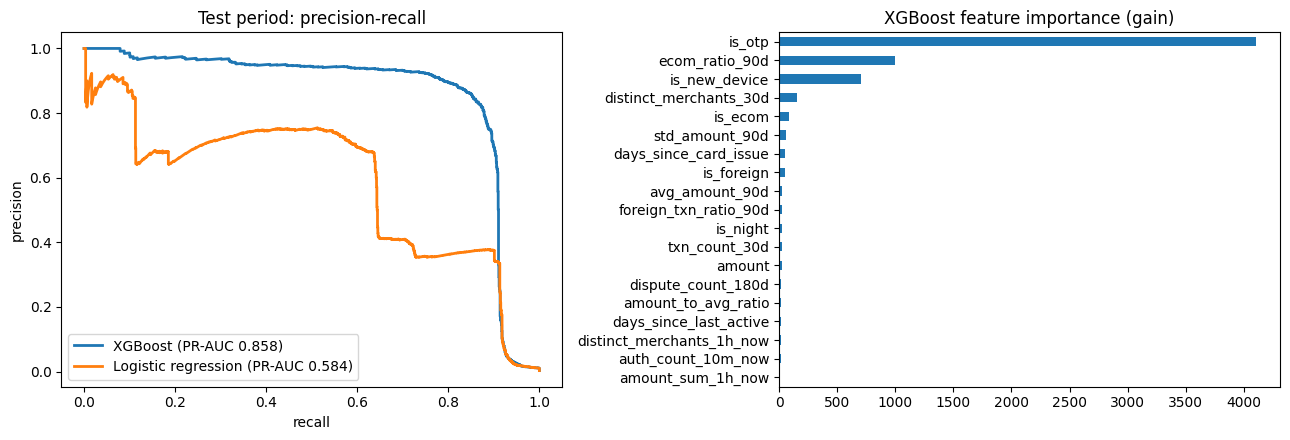

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ev.pr_curve(test.is_fraud.to_numpy(), s_test, "XGBoost", ax[0])
ev.pr_curve(test.is_fraud.to_numpy(), b_test, "Logistic regression", ax[0])
ax[0].set(xlabel="recall", ylabel="precision", title="Test period: precision-recall")
ax[0].legend()
imp = pd.Series(booster.get_score(importance_type="gain")).sort_values()
imp.plot.barh(ax=ax[1], title="XGBoost feature importance (gain)")
plt.tight_layout()

In [12]:
ev.decision_table(test.is_fraud.to_numpy(), s_test, t)

is_fraud,0,1
decision,,
approve,464380,123
decline,507,1277
step_up,4459,26


## 7. Track in MLflow

The notebook logs an experiment run (params, data versions, metrics, PR curve) without registering a model;
registration and the `challenger` alias are the pipeline's job, after its evaluation gate.

In [13]:
reg = ModelRegistry()
run_id = reg.start({"source": "notebook"})
reg.log(run_id, params={"label_as_of": LABEL_AS_OF, "negative_rate": NEGATIVE_RATE, "feature_service": SERVICE,
                        **{f"data_version.{k}": v for k, v in svc.data_versions().items()},
                        **{f"xgb.{k}": v for k, v in trainer.xgb_params.items()}},
        metrics={f"test.{k}": v for k, v in metrics["xgboost"].items()})
reg.log_figure(run_id, fig, "pr_curve_and_importance.png")
print("MLflow run", run_id)
spark.stop()

MLflow run 9ae007ce3681462aba370b9abe27f0b8
